In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.transform import resize
%config InlineBackend.figure_format = 'retina'

## Image Preprocessing

In [2]:
def preprocess_images(size=128, sigma=0.1, seed=42):
    rng = np.random.default_rng(seed)

    raw_images = {
        "Book": data.page(),
        "Coins": data.coins(),
        "Cameraman": data.camera()
    }

    images = {}

    for name, image in raw_images.items():

        # Normalize and resize
        original = img_as_float(image)
        original = resize(original, (size, size),
                          anti_aliasing=True)

        # Add Gaussian noise
        noise = rng.normal(0, sigma, original.shape)
        noisy = np.clip(original + noise, 0, 1)

        # Store flattened image vectors
        images[name] = {
            "original": original.flatten(),
            "noisy": noisy.flatten(),
            "shape": original.shape
        }

    return images

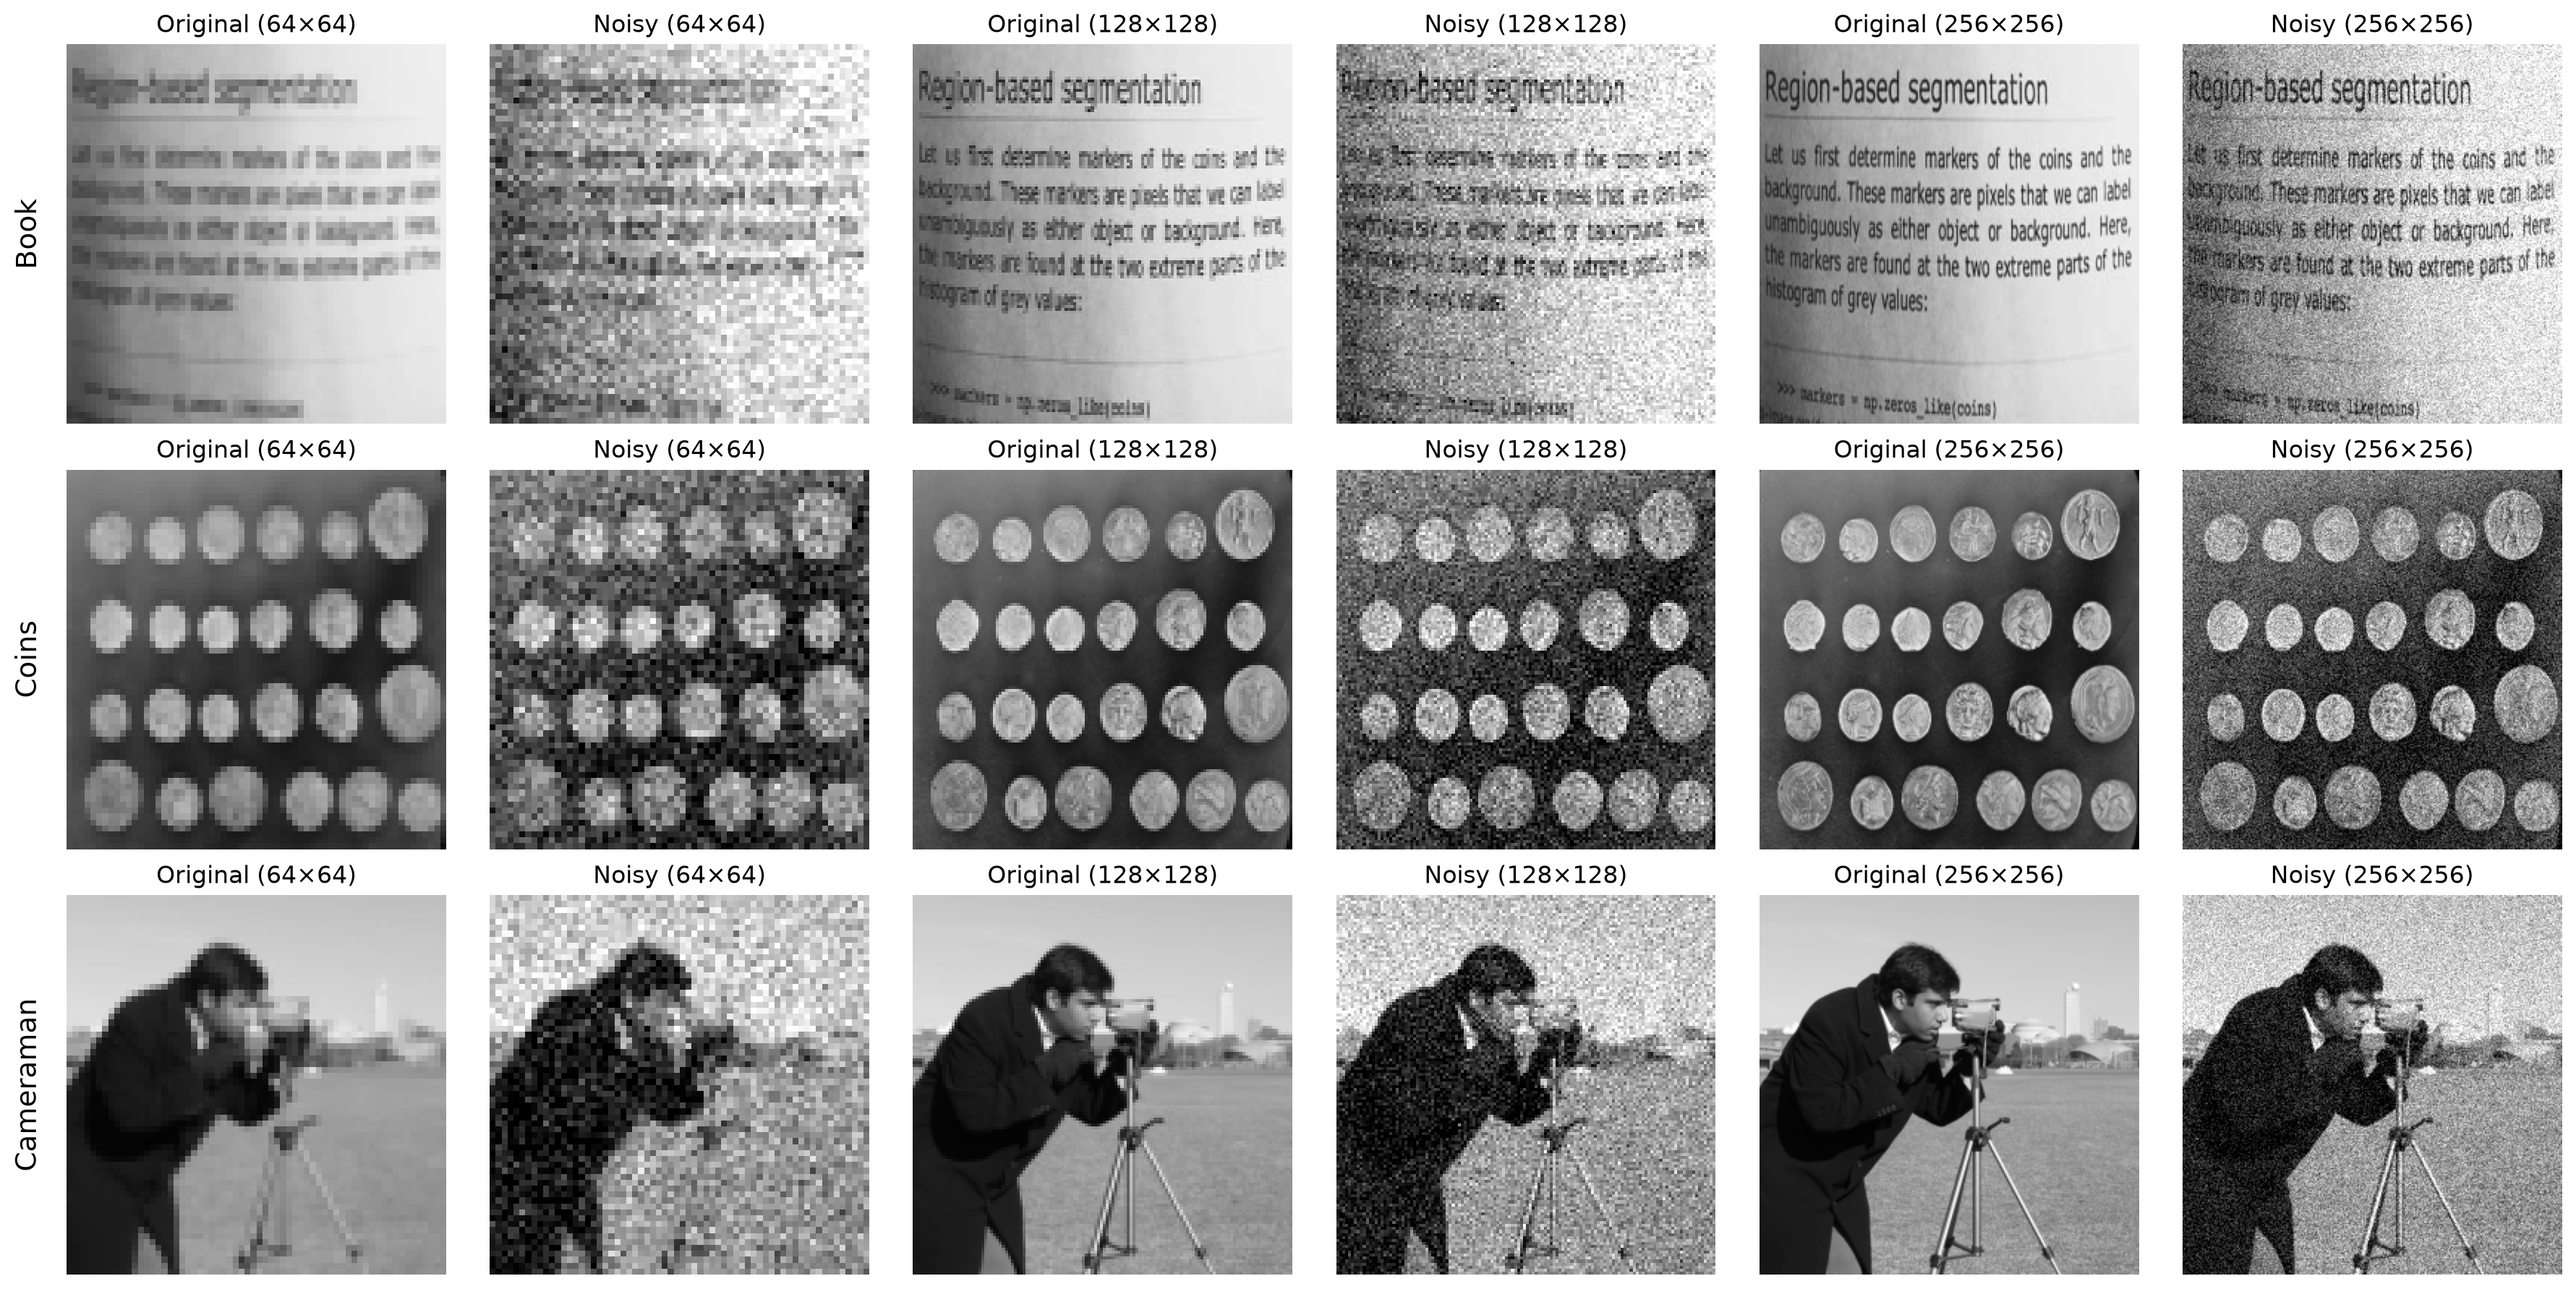

In [3]:
sizes = [64, 128, 256]
names = ["Book", "Coins", "Cameraman"]

images_by_size = {
    size: preprocess_images(size=size, sigma=0.1, seed=42)
    for size in sizes
}

fig, axes = plt.subplots(3, 6, figsize=(18, 9))

for i, name in enumerate(names):
    for j, size in enumerate(sizes):

        image = images_by_size[size][name]
        shape = image["shape"]

        for k, kind in enumerate(["original", "noisy"]):

            ax = axes[i, 2*j + k]

            ax.imshow(
                image[kind].reshape(shape),
                cmap="gray", vmin=0, vmax=1
            )

            ax.set_title(f"{kind.capitalize()} ({size}×{size})")
            ax.axis("off")

    axes[i, 0].text(
        -0.1, 0.5, name,
        transform=axes[i, 0].transAxes,
        rotation=90, va="center", ha="center",
        fontsize=14
    )

plt.tight_layout()
plt.show()

**Note:** All preprocessed images are stored in the `images_by_size` dictionary, indexed first by resolution (`64`, `128`, `256`) and then by image name (`"Book"`, `"Coins"`, `"Cameraman"`). Each entry contains the original image vector, noisy image vector, and image dimensions. The cell below demonstrates how to access these values for use in the denoising algorithms.

In [4]:
image = images_by_size[128]["Cameraman"]

noisy_image = image["noisy"]
original_image = image["original"]
image_shape = image["shape"]

## Algorithm #1: Steepest Descent

## Algorithm #2: Conjugate Gradient